# DiffusionRegPose: the path to an efficient development model

This report summarizes the journey from the external DiffusionRegPose implementation to the native, faster development model. It uses existing run artifacts and keeps checkpoint evaluation, training trajectories, resolution changes, query reductions, and architectural reductions distinct.

The final selected-layer transfer model uses a 3-layer encoder and 3-layer decoder initialized from EDPose layers 2, 4, and 6. It reached 0.6302 validation keypoint AP and 0.5964 bbox AP at 256/427 resolution after 80 epochs.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'results').exists() and (ROOT.parent / 'results').exists():
    ROOT = ROOT.parent
assert (ROOT / 'results').exists(), f'Run this notebook from the repository: {ROOT}'
GAP_DIR = ROOT / 'reports' / 'diffusionregpose_training_gap'
RUNTIME_DIR = ROOT / 'reports' / 'diffusionregpose_runtime'

def artifact(relative_path):
    path = ROOT / relative_path
    assert path.exists(), f'Missing artifact: {path}'
    return path

def load_ap_history(path):
    frame = pd.read_csv(path)
    required = {'epoch', 'ap-val/crowdpose/AP', 'ap-val/crowdpose/bbox/AP'}
    missing = required - set(frame.columns)
    assert not missing, f'{path} is missing {missing}'
    frame = frame[frame['ap-val/crowdpose/AP'].notna()].copy()
    frame['epoch'] = frame['epoch'].astype(int) + 1
    return frame.rename(columns={'ap-val/crowdpose/AP': 'keypoint_ap', 'ap-val/crowdpose/bbox/AP': 'bbox_ap'})[['epoch', 'keypoint_ap', 'bbox_ap']]


## 1. Evidence and provenance

The official and external numbers come from the existing training-gap artifacts generated from the external evaluator. Native trajectories come from native CSV logs. The native full-size trajectory contains reconstructed epochs 10–60 records because an earlier resume attempt overwrote the original logger; that caveat is retained in the source report.

In [2]:
artifact_paths = {
    'official checkpoint': artifact('external/DiffusionRegPose/pretrain_models/diffusionregpose_r50_crowdpose.pth'),
    'official evaluation result': artifact('external/DiffusionRegPose/logs/crowdpose_r50_supplied_evalresult_crowdpose.json'),
    'external reproduction checkpoint': artifact('external/DiffusionRegPose/logs/crowdpose_r50_effective_batch8_resume80/checkpoint.pth'),
    'native full-size trajectory': artifact('reports/diffusionregpose_training_gap/native_trajectory.csv'),
    'native full-size config': artifact('results/diffusionregpose_paper_full/diffusionregpose_paper_full/20260903_000016/.hydra/config.yaml'),
    'native 256/fewer-query trajectory': artifact('results/diffusionregpose_development_compatible_256/dev256-compatible-full/20260910_075409/csv_logs/metrics.csv'),
    'native 128/fewer-query trajectory': artifact('results/diffusionregpose_development_compatible_128/dev128-compatible-full/20260910_143028/csv_logs/metrics.csv'),
    'native selected-layer trajectory': artifact('results/diffusionregpose_development_compatible_256_keep_layers/diffusionregpose_development_compatible_256_keep_layers/20260912_000637/csv_logs/metrics.csv'),
    'selected-layer config': artifact('results/diffusionregpose_development_compatible_256_keep_layers/diffusionregpose_development_compatible_256_keep_layers/20260912_000637/.hydra/config.yaml'),
    'runtime comparison': artifact('reports/diffusionregpose_runtime/runtime_comparison.csv'),
    'parameter comparison': artifact('reports/diffusionregpose_runtime/parameter_comparison.csv'),
}
provenance = pd.DataFrame({'artifact': list(artifact_paths), 'path': [str(path.relative_to(ROOT)) for path in artifact_paths.values()]})
display(provenance)
official_result_records = json.loads(artifact_paths['official evaluation result'].read_text())
print(f'Official result file contains {len(official_result_records):,} serialized predictions.')

,artifact,path
0,official checkpoint,external/DiffusionRegPose/pretrain_models/diff...
1,official evaluation result,external/DiffusionRegPose/logs/crowdpose_r50_s...
2,external reproduction checkpoint,external/DiffusionRegPose/logs/crowdpose_r50_e...
3,native full-size trajectory,reports/diffusionregpose_training_gap/native_t...
4,native full-size config,results/diffusionregpose_paper_full/diffusionr...
5,native 256/fewer-query trajectory,results/diffusionregpose_development_compatibl...
6,native 128/fewer-query trajectory,results/diffusionregpose_development_compatibl...
7,native selected-layer trajectory,results/diffusionregpose_development_compatibl...
8,selected-layer config,results/diffusionregpose_development_compatibl...
9,runtime comparison,reports/diffusionregpose_runtime/runtime_compa...


Official result file contains 142,119 serialized predictions.


## 2. External and native full-size AP

The released external checkpoint is the evaluator anchor. The external reproduction and native full-size rows are trained models. Both the best and final native checkpoints are included because the native trajectory improved through roughly epoch 50 and then regressed.

,category,run,keypoint AP,bbox AP,evaluation
0,External reference,Official released checkpoint,0.7268,0.6310,all-test official
1,External training,"External reproduction, epoch 80",0.6880,0.6206,all-test external
2,Native full-size,"Native best, epoch 50",0.7005,0.6202,all-test native validation
3,Native full-size,"Native final, epoch 80",0.6745,0.5925,all-test native validation


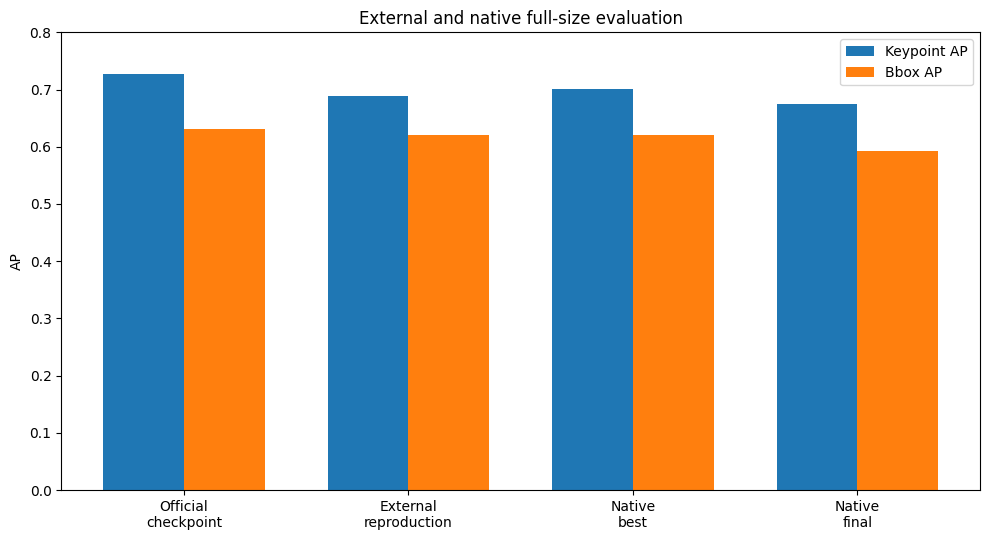

In [3]:
comparison = pd.read_csv(GAP_DIR / 'ap_comparison.csv')
comparison.insert(0, 'category', ['External reference', 'External training', 'Native full-size', 'Native full-size'])
comparison.rename(columns={'keypoint_ap': 'keypoint AP', 'bbox_ap': 'bbox AP'}, inplace=True)
display(comparison.style.format({'keypoint AP': '{:.4f}', 'bbox AP': '{:.4f}'}))

figure, axis = plt.subplots(figsize=(10, 5.5))
positions = range(len(comparison))
width = 0.36
axis.bar([p - width / 2 for p in positions], comparison['keypoint AP'], width, label='Keypoint AP')
axis.bar([p + width / 2 for p in positions], comparison['bbox AP'], width, label='Bbox AP')
axis.set_xticks(list(positions), ['Official\ncheckpoint', 'External\nreproduction', 'Native\nbest', 'Native\nfinal'])
axis.set_ylim(0, 0.8)
axis.set_ylabel('AP')
axis.set_title('External and native full-size evaluation')
axis.legend()
figure.tight_layout()
plt.show()

The released checkpoint scored **0.7268 keypoint AP / 0.6310 bbox AP**. Our external-code reproduction reached **0.6880 / 0.6206** after 80 epochs. The native full-size run reached **0.7005 / 0.6202** at its best point and ended at **0.6745 / 0.5925**. Native evaluation of the released checkpoint reproduced its reported keypoint AP, so the early zero-AP observations were not explained by a universally broken evaluator.

## 3. Efficiency path

The first compact model reduced feature levels, FFN width, query groups, and transformer depth together. It was fast but not a useful learning proxy. The later compatible presets preserved EDPose tensor shapes and reduced query-side work first. The final selected-layer preset then reduced transformer depth while explicitly remapping EDPose layers 2/4/6.

In [4]:
architecture = pd.DataFrame([
    ('Paper/reference architecture', '800–1333', 900, 100, '6 / 6', 2, 100, '49.53M', 'Exact architecture target'),
    ('Native full-size training', '800–1333', 900, 100, '6 / 6', 2, 100, '49.53M', 'Best 0.7005 AP'),
    ('Native 256 query reduction', '256 / 427', 200, 50, '6 / 6', 2, 50, '49.53M', '0.5634 AP at epoch 20'),
    ('Native 128 query reduction', '128 / 192', 200, 50, '6 / 6', 2, 50, '49.53M', '0.5458 AP at epoch 80'),
    ('Earlier compact diagnostic', '256 / 427', 200, 20, '2 / 3', 2, 20, '31.50M', '0.0006 AP at epoch 60'),
    ('Selected-layer transfer model', '256 / 427', 200, 50, '3 / 3', 1, 50, '40.51M', '0.6302 AP at epoch 80'),
], columns=['variant', 'image short/max', 'initial queries', 'groups/proposals', 'encoder / decoder', 'box stages', 'DN queries', 'unique parameters', 'result'])
display(architecture)

runtime = pd.read_csv(RUNTIME_DIR / 'runtime_comparison.csv')
display(runtime[['variant', 'batch_size', 'image_shape', 'update_median_ms', 'images_per_second', 'peak_allocated_gib']].style.format({'update_median_ms': '{:.1f}', 'images_per_second': '{:.2f}', 'peak_allocated_gib': '{:.2f}'}))

,variant,image short/max,initial queries,groups/proposals,encoder / decoder,box stages,DN queries,unique parameters,result
0,Paper/reference architecture,800–1333,900,100,6 / 6,2,100,49.53M,Exact architecture target
1,Native full-size training,800–1333,900,100,6 / 6,2,100,49.53M,Best 0.7005 AP
2,Native 256 query reduction,256 / 427,200,50,6 / 6,2,50,49.53M,0.5634 AP at epoch 20
3,Native 128 query reduction,128 / 192,200,50,6 / 6,2,50,49.53M,0.5458 AP at epoch 80
4,Earlier compact diagnostic,256 / 427,200,20,2 / 3,2,20,31.50M,0.0006 AP at epoch 60
5,Selected-layer transfer model,256 / 427,200,50,3 / 3,1,50,40.51M,0.6302 AP at epoch 80


,variant,batch_size,image_shape,update_median_ms,images_per_second,peak_allocated_gib
0,"Paper, batch 1",1,800x1216,380.9,2.63,4.04
1,"Low-res full, batch 8",8,192x192,739.8,10.81,8.10
2,"Compact 256, batch 8",8,191x192,293.5,27.26,1.59
3,"Compact 192, batch 8",8,192x192,300.4,26.63,1.17
4,"Development, batch 16",16,191x192,414.7,38.58,1.56
5,"Tiny 128, batch 8",8,191x191,231.0,34.63,0.69


The runtime audit measured the paper-sized update at 380.9 ms for batch 1 and the compact 192-pixel development update at 293.5 ms for batch 8. These are not an isolated architecture comparison because batch sizes differ. The practical speedup came from combining lower resolution, fewer query groups, narrower/decreased transformer work, and larger batches.

## 4. Native AP trajectories

The two compatible query-reduction runs and the selected-layer run are plotted alongside the native full-size trajectory. The 256 query-reduction run was stopped at epoch 20; the 128 run completed 80 epochs.

,run,evaluated through epoch,best epoch,best keypoint AP,last bbox AP
0,Native full-size,80,50,0.7005,0.5925
1,Native 256 / 200-query,20,20,0.5634,0.5735
2,Native 128 / 200-query,80,80,0.5458,0.5508
3,Selected layers 256 / 200-query,80,80,0.6302,0.5964


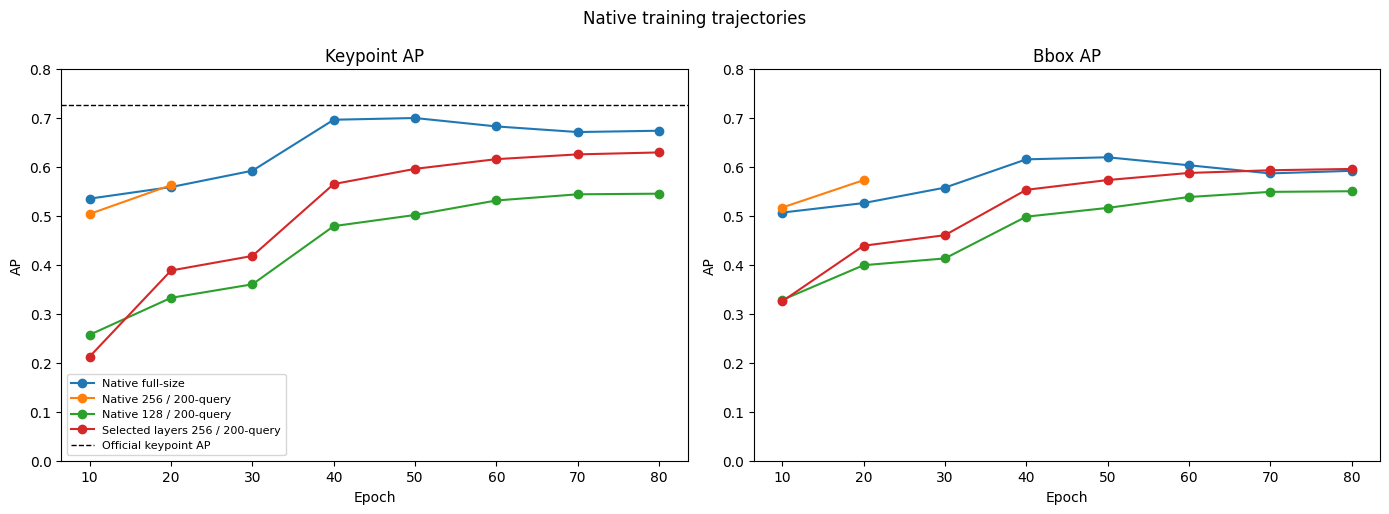

In [5]:
native_full = pd.read_csv(GAP_DIR / 'native_trajectory.csv')
native_256 = load_ap_history(artifact_paths['native 256/fewer-query trajectory'])
native_128 = load_ap_history(artifact_paths['native 128/fewer-query trajectory'])
selected = load_ap_history(artifact_paths['native selected-layer trajectory'])
histories = {'Native full-size': native_full, 'Native 256 / 200-query': native_256, 'Native 128 / 200-query': native_128, 'Selected layers 256 / 200-query': selected}
summary_rows = []
for name, frame in histories.items():
    best = frame.loc[frame['keypoint_ap'].idxmax()]
    last = frame.iloc[-1]
    summary_rows.append({'run': name, 'evaluated through epoch': int(last['epoch']), 'best epoch': int(best['epoch']), 'best keypoint AP': best['keypoint_ap'], 'last bbox AP': last['bbox_ap']})
summary = pd.DataFrame(summary_rows)
display(summary.style.format({'best keypoint AP': '{:.4f}', 'last bbox AP': '{:.4f}'}))

figure, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for name, frame in histories.items():
    axes[0].plot(frame['epoch'], frame['keypoint_ap'], marker='o', label=name)
    axes[1].plot(frame['epoch'], frame['bbox_ap'], marker='o', label=name)
axes[0].axhline(0.726776, color='black', linestyle='--', linewidth=1, label='Official keypoint AP')
axes[0].set_title('Keypoint AP')
axes[1].set_title('Bbox AP')
for axis in axes:
    axis.set_xlabel('Epoch')
    axis.set_ylabel('AP')
    axis.set_ylim(0, 0.8)
axes[0].legend(fontsize=8)
figure.suptitle('Native training trajectories')
figure.tight_layout()
plt.show()

## 5. What we ended up with

The final development model is the selected-layer transfer preset:

- 3 encoder layers and 3 decoder layers.
- EDPose checkpoint layers 2, 4, and 6 remapped into local layers 0, 1, and 2.
- One box stage followed by two pose-refinement stages.
- Separate loading of the original expansion pose head.
- 200 initial queries, 50 proposals/groups, and 50 denoising queries.
- 256/427 resizing, full CrowdPose data, batch size 4, and gradient accumulation 2.
- 40.51M total parameters, 40.29M trainable with the standard stem/`layer1` freeze.

At epoch 80 it achieved **0.6302 keypoint AP / 0.5964 bbox AP**. Validation loss decreased from 19.70 at epoch 10 to 9.57 at epoch 80, and AP was still increasing slowly at the end.

This is not a paper-parity evaluator: it uses lower-resolution images and skips transformer layers. Its value is that it is substantially cheaper to iterate with while still learning meaningful poses.

In [6]:
assert len(comparison) == 4
assert comparison[['keypoint AP', 'bbox AP']].notna().all().all()
for name, frame in histories.items():
    assert not frame.empty, name
    assert frame[['keypoint_ap', 'bbox_ap']].notna().all().all(), name
print('Report integrity checks passed.')

Report integrity checks passed.
